# DIP Lab 03 – Lọc ảnh: Khử nhiễu, Làm nét, Lọc miền tần số
| # | Yêu cầu | Input | Output |
|---|---|---|---|
| 1 | Denoise: ≥ 2 bộ lọc (Median, Bilateral, Non-local Means) | `city_noised.jpg` | ảnh khử nhiễu + PSNR |
| 2 | Sharpening: Unsharp masking + 1 bộ lọc khác | `cat_blurred.jpg` | ảnh làm nét + PSNR |
| 3 | Frequency filtering: band-stop (Ideal/Gaussian) | `xray_noisy.jpg` | ảnh đã lọc + PSNR |

`city_denoised.jpg`, `cat_sharpened.jpg`, `xray_filtered.jpg` là **ảnh chuẩn (ground truth)** để tính PSNR.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)


def read(name, flags=cv2.IMREAD_COLOR):
    img = cv2.imread(str(DATA_DIR / name), flags)
    if img is None:
        raise FileNotFoundError(DATA_DIR / name)
    return img


def psnr(ground_truth, test_image):
    mse = np.mean((ground_truth.astype(np.float64) - test_image.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else float(10 * np.log10(255.0 ** 2 / mse))


def show_grid(images, titles, shape, figsize, save_as, gray=False):
    fig, axes = plt.subplots(*shape, figsize=figsize)
    for ax, img, title in zip(np.ravel(axes), images, titles):
        if gray:
            ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title, fontsize=12, fontweight="bold")
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / save_as, dpi=150, bbox_inches="tight")
    plt.show()

## Bài 1 – Khử nhiễu: Median & Bilateral

PSNR ảnh nhiễu so với ảnh chuẩn: 20.32 dB

Median – kernel: {3: 30.92, 5: 32.73, 7: 30.82}
Bilateral – σ_color: {75: 22.44, 150: 27.15, 300: 32.28}



PSNR Median (k=5)            : 32.7277 dB
PSNR Bilateral (σ_color=300) : 32.2758 dB


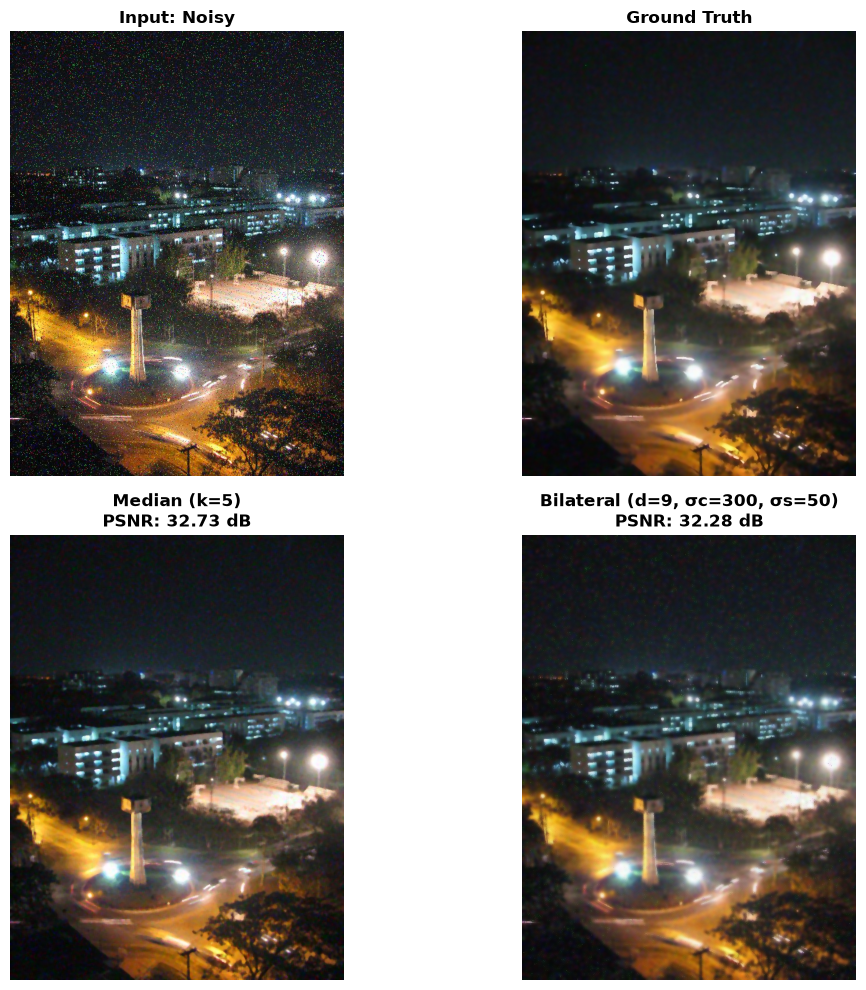

In [2]:
noisy = read("city_noised.jpg")
clean = read("city_denoised.jpg")
print(f"PSNR ảnh nhiễu so với ảnh chuẩn: {psnr(clean, noisy):.2f} dB\n")

# Chọn tham số bằng cách quét và so PSNR
print("Median – kernel:", {k: round(psnr(clean, cv2.medianBlur(noisy, k)), 2) for k in (3, 5, 7)})
print("Bilateral – σ_color:", {s: round(psnr(clean, cv2.bilateralFilter(noisy, 9, s, 50)), 2) for s in (75, 150, 300)})

median = cv2.medianBlur(noisy, 5)
bilateral = cv2.bilateralFilter(noisy, d=9, sigmaColor=300, sigmaSpace=50)
cv2.imwrite(str(OUTPUT_DIR / "city_denoised_median.jpg"), median)
cv2.imwrite(str(OUTPUT_DIR / "city_denoised_bilateral.jpg"), bilateral)
print(f"\nPSNR Median (k=5)            : {psnr(clean, median):.4f} dB")
print(f"PSNR Bilateral (σ_color=300) : {psnr(clean, bilateral):.4f} dB")

show_grid([noisy, clean, median, bilateral],
          ["Input: Noisy", "Ground Truth",
           f"Median (k=5)\nPSNR: {psnr(clean, median):.2f} dB",
           f"Bilateral (d=9, σc=300, σs=50)\nPSNR: {psnr(clean, bilateral):.2f} dB"],
          (2, 2), (12, 10), "comparison_denoise.jpg")

## Bài 2 – Làm nét: Unsharp masking & Laplacian
**Kiểm tra ảnh chuẩn trước:** nếu ảnh "chuẩn" gần như giống ảnh mờ thì PSNR không đo được hiệu quả làm nét.
Dùng thêm **độ nét = phương sai của Laplacian** (không cần ảnh tham chiếu, càng lớn càng nét).

In [3]:
def sharpness(image):
    return cv2.Laplacian(cv2.cvtColor(image, cv2.COLOR_BGR2GRAY), cv2.CV_64F).var()


blurred = read("cat_blurred.jpg")
target = read("cat_sharpened.jpg")
diff = np.abs(target.astype(int) - blurred.astype(int))
print(f"PSNR(ảnh mờ, ảnh chuẩn) = {psnr(target, blurred):.2f} dB, chênh lệch tối đa = {diff.max()} mức xám")
print(f"Độ nét ảnh mờ = {sharpness(blurred):.1f}, ảnh 'chuẩn' = {sharpness(target):.1f}")
print("→ Ảnh chuẩn gần như giống ảnh mờ: làm nét càng mạnh thì PSNR càng giảm. Dùng tham số kinh điển + đo thêm độ nét.")

PSNR(ảnh mờ, ảnh chuẩn) = 51.75 dB, chênh lệch tối đa = 5 mức xám
Độ nét ảnh mờ = 4.4, ảnh 'chuẩn' = 3.6
→ Ảnh chuẩn gần như giống ảnh mờ: làm nét càng mạnh thì PSNR càng giảm. Dùng tham số kinh điển + đo thêm độ nét.


Ảnh                      PSNR     Độ nét
Input (blurred)      51.75 dB        4.4


Unsharp masking      45.81 dB       15.4
Laplacian            43.48 dB       63.8


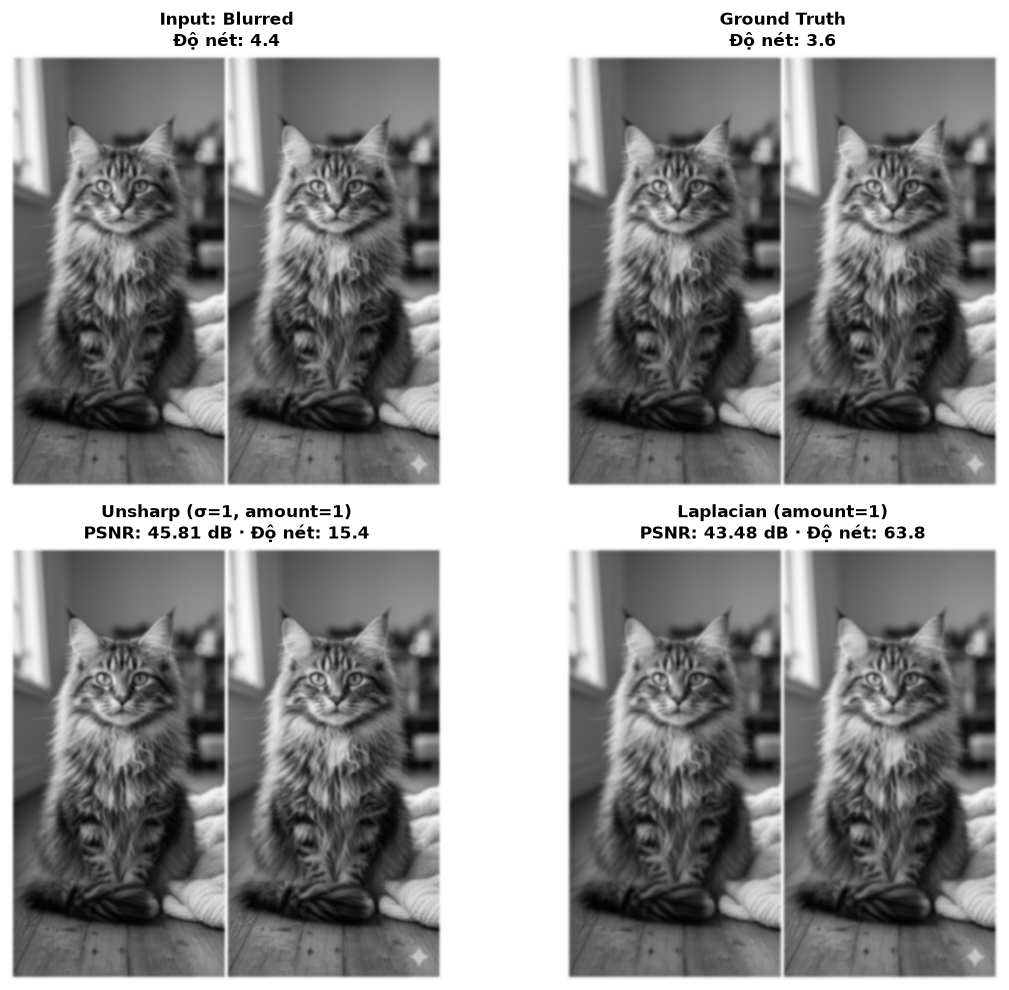

In [4]:
def unsharp_masking(image, ksize=(5, 5), sigma=1.0, amount=1.0):
    """sharp = img + amount·(img − blur). Tính bằng float để giữ cả phần mask âm (làm tối mép)."""
    img = image.astype(np.float32)
    blur = cv2.GaussianBlur(img, ksize, sigma)
    return np.clip(img + amount * (img - blur), 0, 255).astype(np.uint8)


def laplacian_sharpening(image, amount=1.0):
    """sharp = img − amount·∇²img (kernel 4-connected, tâm dương nên phải TRỪ)."""
    kernel = np.array([[0, -1, 0], [-1, 4, -1], [0, -1, 0]], dtype=np.float32)
    img = image.astype(np.float32)
    return np.clip(img - amount * cv2.filter2D(img, -1, kernel), 0, 255).astype(np.uint8)


sharp_unsharp = unsharp_masking(blurred)
sharp_laplace = laplacian_sharpening(blurred)
cv2.imwrite(str(OUTPUT_DIR / "cat_sharpened_unsharp.jpg"), sharp_unsharp)
cv2.imwrite(str(OUTPUT_DIR / "cat_sharpened_laplace.jpg"), sharp_laplace)

print(f"{'Ảnh':18s} {'PSNR':>10s} {'Độ nét':>10s}")
for name, img in [("Input (blurred)", blurred), ("Unsharp masking", sharp_unsharp), ("Laplacian", sharp_laplace)]:
    print(f"{name:18s} {psnr(target, img):>7.2f} dB {sharpness(img):>10.1f}")

show_grid([blurred, target, sharp_unsharp, sharp_laplace],
          [f"Input: Blurred\nĐộ nét: {sharpness(blurred):.1f}", f"Ground Truth\nĐộ nét: {sharpness(target):.1f}",
           f"Unsharp (σ=1, amount=1)\nPSNR: {psnr(target, sharp_unsharp):.2f} dB · Độ nét: {sharpness(sharp_unsharp):.1f}",
           f"Laplacian (amount=1)\nPSNR: {psnr(target, sharp_laplace):.2f} dB · Độ nét: {sharpness(sharp_laplace):.1f}"],
          (2, 2), (12, 10), "comparison_sharpen.jpg")

Phóng to một vùng để so sánh: Laplacian nét hơn nhiều nhưng làm nổi hạt nhiễu mịn trên vùng phẳng; Unsharp tự nhiên hơn.

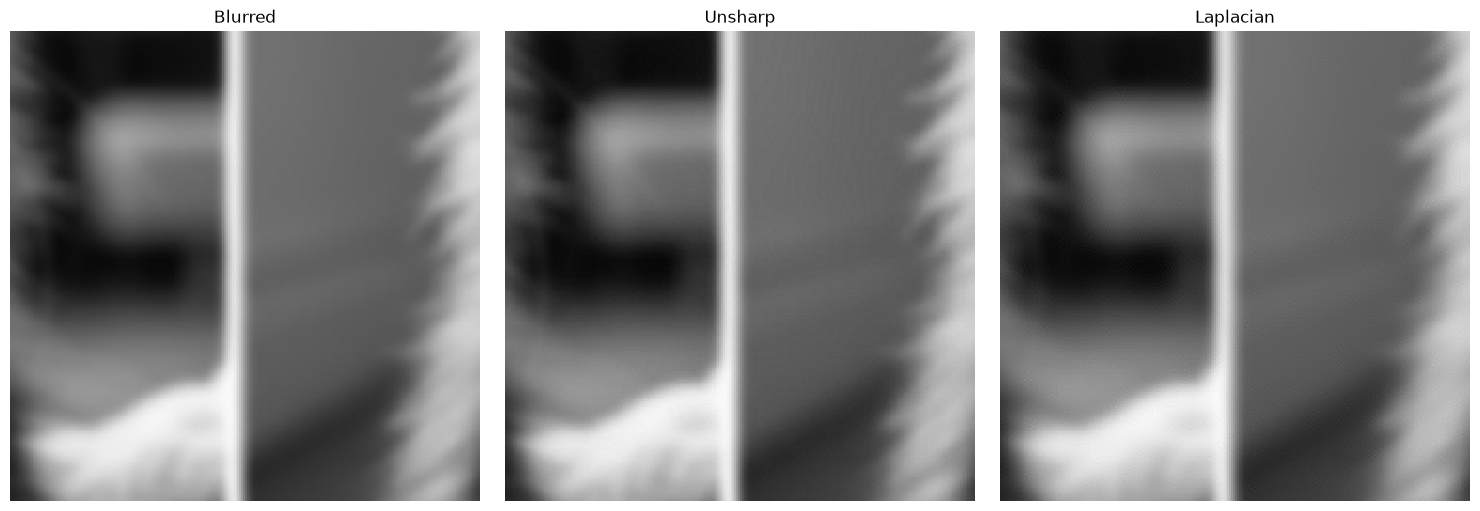

In [5]:
y, x, s = 500, 500, 250
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, title in zip(axes, (blurred, sharp_unsharp, sharp_laplace), ("Blurred", "Unsharp", "Laplacian")):
    ax.imshow(cv2.cvtColor(img[y:y + s, x:x + s], cv2.COLOR_BGR2RGB), interpolation="nearest")
    ax.set_title(title); ax.axis("off")
plt.tight_layout()
plt.show()

## Bài 3 – Lọc miền tần số (Gaussian notch reject)
`FFT → fftshift → nhân mặt nạ H(u, v) → ifftshift → iFFT`. Nhiễu tuần hoàn hiện thành **cặp điểm sáng đối xứng** trong phổ.
### 3.1. Quan sát phổ để tìm vị trí nhiễu

In [6]:
xray_noisy = read("xray_noisy.jpg", cv2.IMREAD_GRAYSCALE)
xray_clean = read("xray_filtered.jpg", cv2.IMREAD_GRAYSCALE)
rows, cols = xray_noisy.shape
cr, cc = rows // 2, cols // 2

F = np.fft.fftshift(np.fft.fft2(xray_noisy.astype(np.float64)))
magnitude = np.log1p(np.abs(F))

search_mag = np.abs(F).copy()
search_mag[cr - 3:cr + 4, cc - 3:cc + 4] = 0  # bỏ vùng tâm (thành phần tần số thấp)
peaks = [np.unravel_index(i, F.shape) for i in np.argsort(search_mag.ravel())[-4:]]
print("Đỉnh mạnh nhất (hàng − tâm, cột − tâm):", sorted({(int(r - cr), int(c - cc)) for r, c in peaks}))

Đỉnh mạnh nhất (hàng − tâm, cột − tâm): [(-26, 0), (-25, 0), (25, 0), (26, 0)]


Các đỉnh nằm tại **(±25, 0)** và **(±26, 0)** → nhiễu nằm trên trục dọc, cách tâm **D0 ≈ 25** (mặt nạ Gaussian W = 5 phủ cả hai).
### 3.2. Thiết kế mặt nạ và lọc

Chọn độ rộng W: {3: 30.61, 5: 31.96, 8: 28.5}
PSNR ảnh nhiễu : 19.7742 dB
PSNR sau lọc   : 31.9610 dB


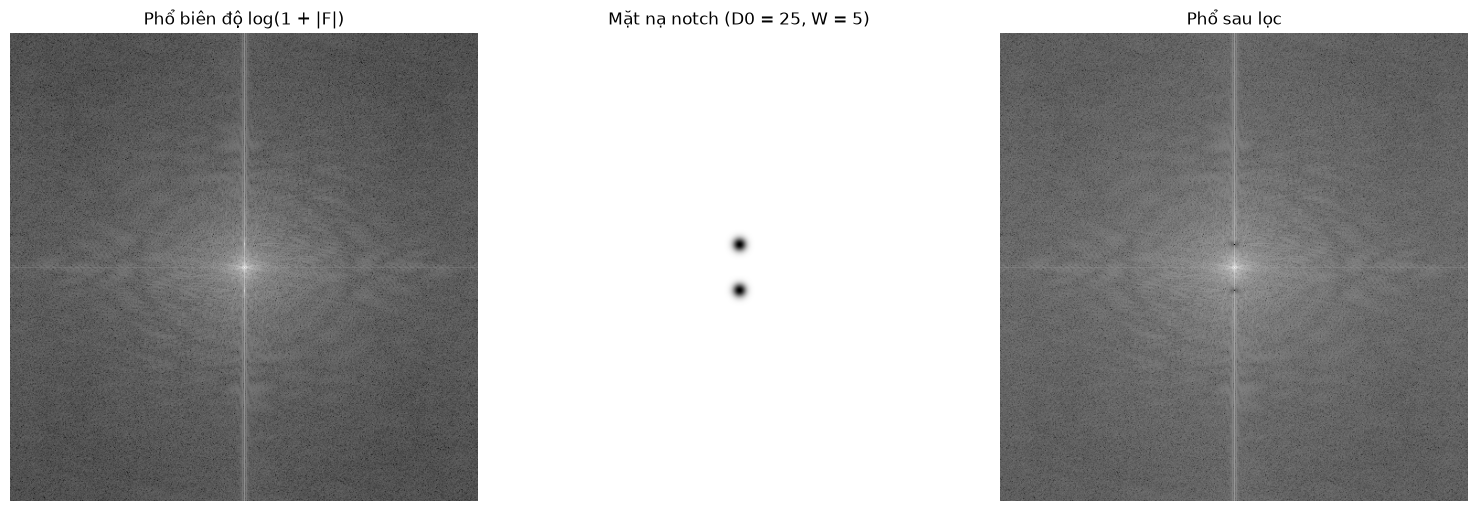

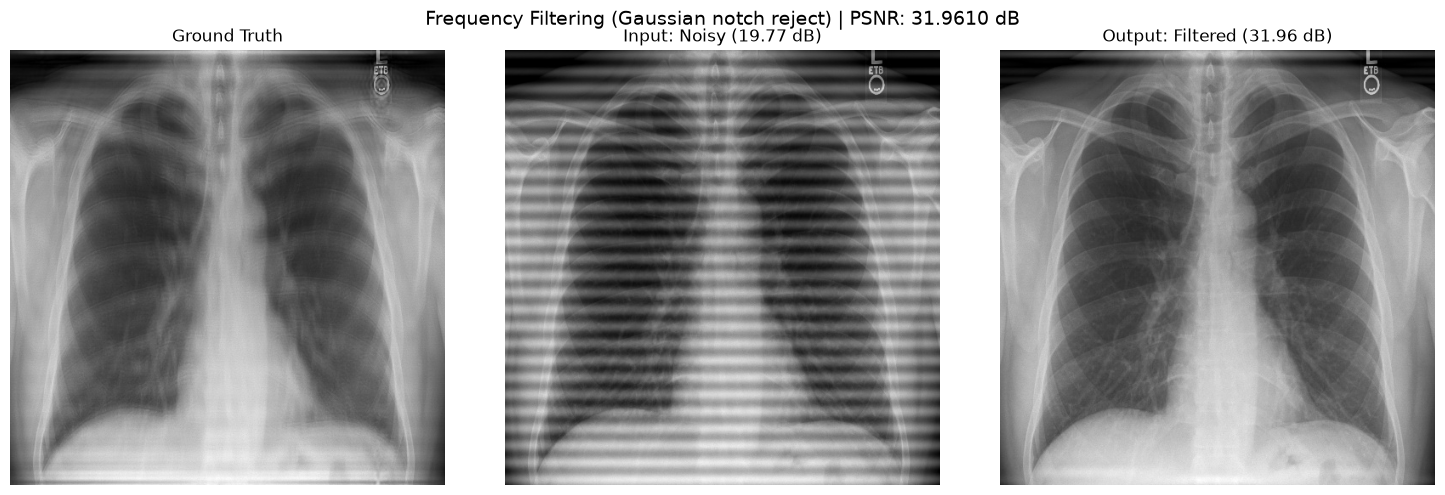

In [7]:
def gaussian_notch_reject(shape, centers, width):
    """H = Π (1 − exp(−D_k² / 2W²)): chặn mềm quanh từng điểm (u_k, v_k)."""
    r, c = shape
    v, u = np.mgrid[0:r, 0:c]
    H = np.ones(shape, dtype=np.float64)
    for (vk, uk) in centers:
        H *= 1.0 - np.exp(-((u - uk) ** 2 + (v - vk) ** 2) / (2.0 * width ** 2))
    return H


def notch_filter(img, D0, W):
    Fs = np.fft.fftshift(np.fft.fft2(img.astype(np.float64)))
    H = gaussian_notch_reject(img.shape, [(cr + D0, cc), (cr - D0, cc)], W)
    g = np.abs(np.fft.ifft2(np.fft.ifftshift(Fs * H)))
    return cv2.normalize(g, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8), H


print("Chọn độ rộng W:", {w: round(psnr(xray_clean, notch_filter(xray_noisy, 25, w)[0]), 2) for w in (3, 5, 8)})
xray_filtered, H = notch_filter(xray_noisy, D0=25, W=5)
cv2.imwrite(str(OUTPUT_DIR / "xray_filtered_result.jpg"), xray_filtered)
print(f"PSNR ảnh nhiễu : {psnr(xray_clean, xray_noisy):.4f} dB")
print(f"PSNR sau lọc   : {psnr(xray_clean, xray_filtered):.4f} dB")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(magnitude, cmap="gray"); axes[0].set_title("Phổ biên độ log(1 + |F|)")
axes[1].imshow(H, cmap="gray"); axes[1].set_title("Mặt nạ notch (D0 = 25, W = 5)")
axes[2].imshow(np.log1p(np.abs(F * H)), cmap="gray"); axes[2].set_title("Phổ sau lọc")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, title in zip(axes, (xray_clean, xray_noisy, xray_filtered),
                          ("Ground Truth", f"Input: Noisy ({psnr(xray_clean, xray_noisy):.2f} dB)",
                           f"Output: Filtered ({psnr(xray_clean, xray_filtered):.2f} dB)")):
    ax.imshow(img, cmap="gray", vmin=0, vmax=255); ax.set_title(title); ax.axis("off")
plt.suptitle(f"Frequency Filtering (Gaussian notch reject) | PSNR: {psnr(xray_clean, xray_filtered):.4f} dB", fontsize=14)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "xray_comparison.jpg", dpi=150, bbox_inches="tight")
plt.show()